# FA-COD v8 — Camouflaged Object Detection on CAMO

## Contents
1. Project Introduction
2. Setup and Configuration
3. Dataset Preparation
4. Data Augmentation
5. Datasets, Weighted Sampler and DataLoaders
6. Model Architecture (overview and encoder)
7. Frequency Enhancement Module
8. Feature Pyramid Network
9. Decoder and Refinement
10. Loss Functions
11. Evaluation Metrics
12. Training and Validation
13. Test Evaluation
14. Qualitative Results
15. Confusion Matrix
16. Ablation Study
17. Final Results and Saved Artifacts

---

## 1. Project Introduction

FA-COD is a Res2Net50-based network for camouflaged object detection (COD). It applies FFT-based frequency enhancement to all four encoder levels, fuses them with a 4-scale feature pyramid, decodes with residual blocks, and sharpens the mask with a Sobel-based boundary refinement module. Auxiliary heads provide deep supervision during training.

This notebook trains and evaluates the model on the **CAMO** dataset (the 1,000-image `Train` folder, split 70 / 15 / 15 with a fixed seed). The recorded run used Google Colab with a Tesla T4 GPU.

> **Version note.** The notebook is **FA-COD v8 = the v7 architecture + three training-recipe fixes.** The model class is still named `FACOD_v7` because the architecture did not change between v7 and v8. Some output files keep legacy `v6` names (Drive folder `FACOD_v6`, checkpoint `facod_v6_best.pth`, results file `results_v6.json`) so that files already saved on Google Drive are still found.

**What v8 changes relative to v7**

1. `OneCycleLR` replaces `CosineAnnealingWarmRestarts`. (In the earlier run that used warm restarts, training early-stopped at epoch 34; that run is not part of this notebook.)
2. Early-stopping patience is raised from 15 to 25 epochs.
3. The per-image Otsu threshold is used only for validation / test (and TTA predictions), not during training.

### What each version contributed

| Component | Origin | Notes |
|-----------|--------|-------|
| **Res2Net50 encoder** | v3 | Multi-scale receptive field inside each block |
| **384×384 input + strong augmentation** | v3 | Better boundary detail; ISONoise / CoarseDropout / MedianBlur |
| **Centroid-based S-measure** | v3 | After Fan et al., ICCV'17 (similarity terms simplified; see Section 11) |
| **Sample-weighted metric accumulation** | v3 | Unbiased averaging across batches |
| **Checkpoint on best S-measure** | v3 | Preserves structural quality |
| **3-tier weighted sampler** | v5 | Small-object images are sampled up to 4× more often |
| **Tversky + FocalBCE loss (rebalanced)** | v5 | Recall-biased: β = 0.6, foreground weight 2.0 |
| **CBAM-style spatial gate in the frequency module** | v5 | Learns *where* to attend, not only *what* texture |
| **Gradient accumulation** | v5 | Effective batch size 16 |
| **6-column prediction figure with error map** | v5 | Shows TP / FN / FP directly |
| **5-pass TTA, fixed threshold 0.42** | v6 | Smoother probability maps, fewer false positives |
| **IoU loss term** | v6 | Direct gradient on overlap |
| **Frequency module on all 4 encoder levels** | v7 | Previously only the two shallower levels |
| **Boundary Refinement Module (Sobel edge cues)** | v7 | Sharper mask boundaries |
| **Auxiliary head `aux2`, label smoothing in FocalBCE** | v7 | Extra deep supervision; reduced over-confidence |
| **ElasticTransform / GridDistortion augmentation** | v7 | Irregular-boundary simulation |
| **Per-image Otsu threshold** | v7 (val/test only since v8) | Fallback to 0.42 when the Otsu threshold is degenerate |
| **OneCycleLR, patience 25** | v8 | Replaces CosineAnnealingWarmRestarts (v3) |

### Course unit mapping

| Unit | Topic | Implementation |
|------|-------|----------------|
| **Unit 1** | CNN Architecture | Res2Net50 encoder, 4-scale features |
| **Unit 2** | Regularization | FFT `FrequencyModule` + spatial gate, `Dropout2d`, strong augmentation |
| **Unit 3** | Representational Power | 4-scale FPN + 4-stage decoder (256→128→64→32) + ablation |
| **Unit 4** | Residual Connections + BatchNorm | `ResDecBlock` everywhere + encoder skip connections |
| **Unit 5** | — | Boundary Refinement Module (added in v7) |

### How to run
Run the cells top to bottom in Google Colab with a GPU runtime. The CAMO dataset must be available under `BASE_DIR` in Google Drive (Section 2.2). Section 2.1 pins only `albumentations==1.3.1`; the other packages are installed unpinned.

> **About the recorded outputs.** All outputs (logs, figures, tables, metrics) are preserved exactly as produced by the original run; only download progress bars and library warnings were removed. Because that run predates this cleanup, a few stored outputs still show labels that the code above them now corrects: "v6" in some banners and figure titles, "CosineWarmRestarts" in the learning-rate panel title, `thresh=0.42` in prediction / confusion-matrix figure titles (thresholding is actually per-image Otsu with 0.42 as fallback), and "per batch" wording in two scheduler printouts. **No metric values are affected.** Re-running a cell refreshes its labels. The last five code cells were executed out of order in the original session (execution counts 45, 42, 28, 29, 30).

## 2. Setup and Configuration

### 2.1 Install dependencies

In [1]:
!pip install -q albumentations==1.3.1 segmentation-models-pytorch timm
print('✅ Done')

✅ Done


### 2.2 Google Drive and paths
Mounts Google Drive and defines the dataset and output locations. `FACOD_v6` is a legacy folder name; it is kept so existing checkpoints and results on Drive are still found.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
BASE_DIR  = '/content/drive/MyDrive/CAMO-V.1.0-CVIU2019'
IMAGE_DIR = os.path.join(BASE_DIR, 'Images', 'Train')
MASK_DIR  = os.path.join(BASE_DIR, 'GT')
SAVE_DIR  = '/content/drive/MyDrive/FACOD_v6'   # legacy folder name (kept for compatibility)
os.makedirs(SAVE_DIR, exist_ok=True)
print('Images :', IMAGE_DIR)
print('Masks  :', MASK_DIR)
print('Output :', SAVE_DIR)

Images : /content/drive/MyDrive/CAMO-V.1.0-CVIU2019/Images/Train
Masks  : /content/drive/MyDrive/CAMO-V.1.0-CVIU2019/GT
Output : /content/drive/MyDrive/FACOD_v6


### 2.3 Imports, seeds and device
Fixes random seeds and enables deterministic cuDNN behaviour (`benchmark=False`) for reproducibility.

In [4]:
import os, random, warnings
warnings.filterwarnings('ignore')
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import segmentation_models_pytorch as smp
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
from sklearn.metrics import confusion_matrix
import json

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
if device.type == 'cuda':
    print('GPU   :', torch.cuda.get_device_name(0))
    print('VRAM  :', round(torch.cuda.get_device_properties(0).total_memory/1e9, 1), 'GB')

Device: cuda
GPU   : Tesla T4
VRAM  : 15.6 GB


## 3. Dataset Preparation

### 3.1 Dataset configuration and class
`CamoSubset` loads an image / mask pair by index. Masks are read as grayscale and scaled to [0, 1]. Image and mask file names are matched by stem (`.jpg` / `.jpeg` → `.png`).

In [ ]:
IMG_MEAN    = (0.485, 0.456, 0.406)
IMG_STD     = (0.229, 0.224, 0.225)
IMG_SIZE    = 384          # input resolution (384×384)
BATCH       = 4
ACCUM_STEPS = 4            # gradient accumulation → effective batch = BATCH × ACCUM_STEPS = 16
SPLIT_SEED  = 42

class CamoSubset(Dataset):
    def __init__(self, image_dir, mask_dir, indices, transform):
        self.image_dir = image_dir
        self.mask_dir  = mask_dir
        all_imgs       = sorted(os.listdir(image_dir))
        self.images    = [all_imgs[i] for i in indices]
        self.transform = transform

    def __len__(self): return len(self.images)

    def __getitem__(self, i):
        name  = self.images[i]
        img   = cv2.cvtColor(cv2.imread(os.path.join(self.image_dir, name)), cv2.COLOR_BGR2RGB)
        mname = name.replace('.jpg','.png').replace('.jpeg','.png')
        mask  = cv2.imread(os.path.join(self.mask_dir, mname), cv2.IMREAD_GRAYSCALE)
        aug   = self.transform(image=img, mask=mask)
        return aug['image'], aug['mask'].unsqueeze(0).float() / 255.0

### 3.2 Fixed-seed train / validation / test split
The sorted file list is shuffled with `SPLIT_SEED` and cut 70 / 15 / 15. The exact file lists are written to `dataset_split.json` in the output folder, so the split can be reproduced and audited.

In [ ]:
# Fixed-seed 70 / 15 / 15 split (reproducible; the file lists are saved to dataset_split.json)
all_imgs_sorted = sorted(os.listdir(IMAGE_DIR))
all_idx = list(range(len(all_imgs_sorted)))
rng = random.Random(SPLIT_SEED)
rng.shuffle(all_idx)
n = len(all_idx)
n_train = int(0.70 * n)
n_val   = int(0.15 * n)
train_idx = all_idx[:n_train]
val_idx   = all_idx[n_train:n_train+n_val]
test_idx  = all_idx[n_train+n_val:]

split_record = {'seed': SPLIT_SEED, 'n_total': n,
                'n_train': len(train_idx), 'n_val': len(val_idx), 'n_test': len(test_idx),
                'train_files': [all_imgs_sorted[i] for i in train_idx],
                'val_files':   [all_imgs_sorted[i] for i in val_idx],
                'test_files':  [all_imgs_sorted[i] for i in test_idx]}
with open(os.path.join(SAVE_DIR, 'dataset_split.json'), 'w') as f:
    json.dump(split_record, f, indent=2)

## 4. Data Augmentation

Training images use a strong augmentation pipeline (flips, rotation, shift / scale / rotate, colour jitter, noise, blur, coarse dropout and elastic / grid distortion). Validation and test images are only resized and normalised.

In [ ]:
# Training augmentation: geometric + photometric + noise / blur + dropout + elastic / grid distortion
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.RandomRotate90(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.2, rotate_limit=30, border_mode=0, p=0.4),
    A.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05, p=0.5),
    A.OneOf([
        A.GaussNoise(var_limit=(10, 50), p=1),
        A.ISONoise(p=1),
    ], p=0.3),
    A.OneOf([
        A.GaussianBlur(blur_limit=3, p=1),
        A.MedianBlur(blur_limit=3, p=1),
    ], p=0.2),
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32, p=0.2),
    A.OneOf([
        A.ElasticTransform(alpha=1, sigma=50, alpha_affine=50, p=1),
        A.GridDistortion(num_steps=5, distort_limit=0.3, p=1),
    ], p=0.25),   # irregular-boundary simulation (added in v7)
    A.Normalize(mean=IMG_MEAN, std=IMG_STD),
    ToTensorV2()
])
eval_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMG_MEAN, std=IMG_STD),
    ToTensorV2()
])

## 5. Datasets, Weighted Sampler and DataLoaders

### 5.1 Build datasets and loaders
Each training image is assigned a sampling weight from its mask area: **4.0** if the mask covers < 5% of the image, **2.5** if 5–15%, otherwise **1.0**. Weights are computed with the training transform applied, so the tier counts printed below come from a single augmented pass over the training set.

In [5]:
train_dataset = CamoSubset(IMAGE_DIR, MASK_DIR, train_idx, train_transform)
val_dataset   = CamoSubset(IMAGE_DIR, MASK_DIR, val_idx,   eval_transform)
test_dataset  = CamoSubset(IMAGE_DIR, MASK_DIR, test_idx,  eval_transform)

# 3-tier weighted sampler: images with small masks are drawn more often
weights = []
print('Computing 3-tier sample weights...')
for i in range(len(train_dataset)):
    _, msk = train_dataset[i]
    area   = msk.mean().item()
    if   area < 0.05: w = 4.0
    elif area < 0.15: w = 2.5
    else:             w = 1.0
    weights.append(w)

sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH, sampler=sampler,
                          num_workers=2, pin_memory=True, drop_last=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH, shuffle=False,
                          num_workers=2, pin_memory=True)

t1 = sum(1 for w in weights if w == 4.0)
t2 = sum(1 for w in weights if w == 2.5)
t3 = sum(1 for w in weights if w == 1.0)
print(f'Total {n} | Train {len(train_dataset)} | Val {len(val_dataset)} | Test {len(test_dataset)}')
print(f'Tier1 (tiny  <5%):   {t1} samples → 4.0x weight')
print(f'Tier2 (small 5-15%): {t2} samples → 2.5x weight')
print(f'Tier3 (normal >15%): {t3} samples → 1.0x weight')
print(f'Split sanity: no overlap = {len(set(train_idx) & set(val_idx) & set(test_idx)) == 0}')

Computing 3-tier sample weights...
Total 1000 | Train 700 | Val 150 | Test 150
Tier1 (tiny  <5%):   114 samples → 4.0x weight
Tier2 (small 5-15%): 267 samples → 2.5x weight
Tier3 (normal >15%): 319 samples → 1.0x weight
Split sanity: no overlap = True


### 5.2 Visual check of training samples
Random training image / mask pairs after augmentation and normalisation (undone for display).

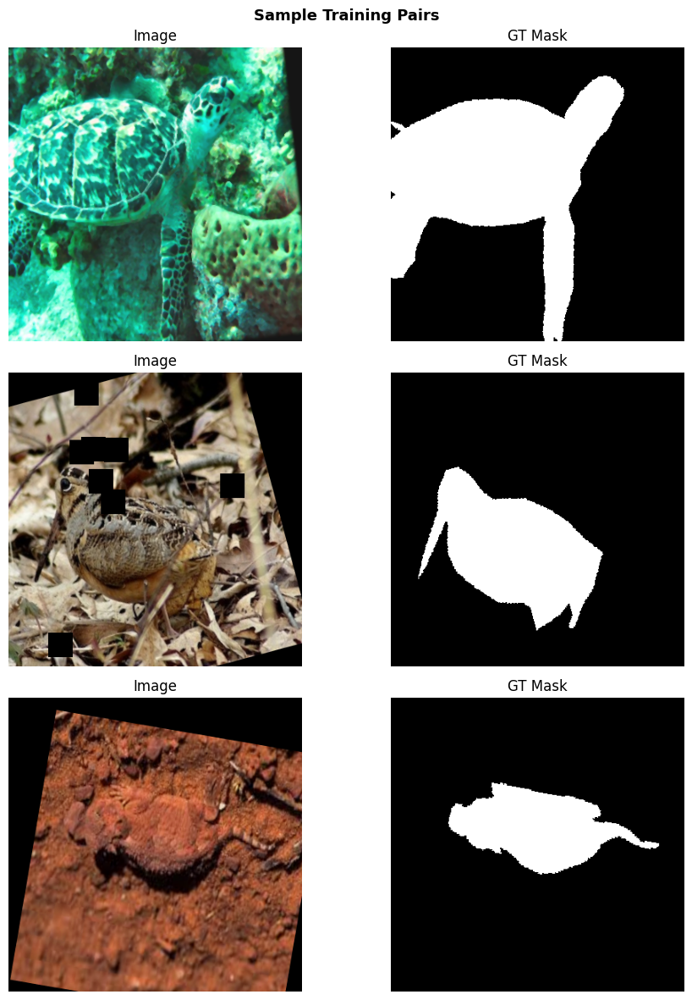

In [6]:
def denorm(t):
    img = t.permute(1,2,0).cpu().numpy()
    return np.clip(img * np.array(IMG_STD) + np.array(IMG_MEAN), 0, 1)

fig, axes = plt.subplots(3, 2, figsize=(10, 12))
fig.suptitle('Sample Training Pairs', fontsize=13, fontweight='bold')
for r in range(3):
    img, msk = train_dataset[random.randint(0, len(train_dataset)-1)]
    axes[r,0].imshow(denorm(img));               axes[r,0].set_title('Image');   axes[r,0].axis('off')
    axes[r,1].imshow(msk.squeeze(), cmap='gray'); axes[r,1].set_title('GT Mask'); axes[r,1].axis('off')
plt.tight_layout(); plt.show()

## 6. Model Architecture

```
Input image [B, 3, 384, 384]
      │
Res2Net50 encoder (timm `res2net50_26w_4s`, ImageNet-pretrained)
      │  C2 (256) · C3 (512) · C4 (1024) · C5 (2048)
      ▼
FrequencyModule ×4  (freq2 … freq5): FFT magnitude / phase channel gate + spatial gate
      ▼
Feature Pyramid Network (RepresentationalFusion): 1×1 lateral → top-down add → ResDecBlock
      │  p2 · p3 · p4 · p5   (256 channels each)
      ▼
Decoder (ResDecBlock ×4 with skip connections)
      dec4: [p5 ⊕ p4↓] → dec3: [d4↑ ⊕ p3] → dec2: [d3↑ ⊕ p2] → dec1: d2↑ to full resolution
      │  channels 256 → 128 → 64 → 32
      ▼
BoundaryRefinementModule (Sobel edges of the channel-mean input image)
      ▼
1×1 head → logits [B, 1, 384, 384]

Training only: auxiliary heads aux2 (on d2), aux3 (on p3), aux4 (on p4) for deep supervision
```

(↑ / ↓ = bilinear resize to the target size, ⊕ = channel concatenation.)

The model is assembled in Section 9.2; the building blocks are defined in Sections 6.1 and 7–9.

### 6.1 Encoder (Unit 1)
Res2Net50 from `timm` with the same channel widths as ResNet-50. `forward` returns a list of six feature maps; the stem output is repeated as placeholder entries so that C2–C5 sit at indices 2–5.

In [ ]:
class Res2NetEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone = timm.create_model(
            'res2net50_26w_4s', pretrained=True,
            features_only=True, out_indices=(0,1,2,3,4)
        )
        self._out_channels = [3, 64, 256, 512, 1024, 2048]

    def forward(self, x):
        feats = self.backbone(x)
        dummy = feats[0]
        return [dummy, dummy, feats[1], feats[2], feats[3], feats[4]]

## 7. Frequency Enhancement Module (Unit 2)

`FrequencyModule` is applied to each encoder level (C2–C5):

1. The feature map is cast to fp32 and transformed with a 2-D FFT; magnitude (normalised per sample) and phase are each passed through a small 1×1-conv gate.
2. The two sigmoid gates are multiplied into a **channel gate** (*what* textures matter).
3. A CBAM-style **spatial gate** (7×7 conv on channel-wise mean / max) then learns *where* to attend.
4. The gated feature is blended residually with the input through a learnable `alpha`, clamped to [0.05, 0.40].

In [ ]:
class FrequencyModule(nn.Module):
    def __init__(self, ch):
        super().__init__()
        mid = max(ch // 8, 16)
        def gate_block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, mid, 1, bias=False), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
                nn.Conv2d(mid, c_out, 1, bias=False), nn.BatchNorm2d(c_out))
        self.mag_gate = gate_block(ch, ch)
        self.pha_gate = gate_block(ch, ch)
        self.spatial_gate = nn.Sequential(
            nn.Conv2d(2, 1, kernel_size=7, padding=3, bias=False),
            nn.BatchNorm2d(1), nn.Sigmoid())
        self.alpha = nn.Parameter(torch.tensor(0.10))

    def forward(self, x):
        orig_dtype = x.dtype
        xf = x.float()           # fp32 for the FFT (avoids cuFFT NaNs on non-power-of-two sizes under AMP)
        F_ = torch.fft.fftshift(torch.fft.fft2(xf, norm='ortho'))
        mag = torch.abs(F_)
        B   = mag.shape[0]
        mag = (mag.view(B,-1) / (mag.view(B,-1).max(1,keepdim=True)[0]+1e-8)).view_as(xf)
        pha = torch.angle(F_)
        mag = mag.to(orig_dtype); pha = pha.to(orig_dtype)
        ch_gate = torch.sigmoid(self.mag_gate(mag)) * torch.sigmoid(self.pha_gate(pha))
        x_ch    = x.to(orig_dtype) * ch_gate
        avg_pool = x_ch.mean(dim=1, keepdim=True)
        max_pool = x_ch.max(dim=1, keepdim=True)[0]
        sp_gate  = self.spatial_gate(torch.cat([avg_pool, max_pool], dim=1))
        x_sp     = x_ch * sp_gate
        a = self.alpha.clamp(0.05, 0.40)
        return x.to(orig_dtype) + a * (x_sp - x.to(orig_dtype))

## 8. Feature Pyramid Network (Unit 3)

### 8.1 Residual block (shared by the FPN and the decoder, Unit 4)
`ResDecBlock`: Conv-BN-ReLU-`Dropout2d`-Conv-BN with a residual connection (a 1×1 conv + BN on the skip path when the channel count changes), followed by ReLU.

In [ ]:
class ResDecBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout=0.1):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Dropout2d(dropout),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch))
        self.skip = (nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch))
            if in_ch != out_ch else nn.Identity())
        self.act = nn.ReLU(inplace=True)

    def forward(self, x): return self.act(self.body(x) + self.skip(x))

### 8.2 Four-scale top-down FPN (`RepresentationalFusion`)
Each encoder level gets a 1×1 lateral projection to 256 channels. Starting from C5, features are merged top-down (bilinear upsample + add) and refined with a `ResDecBlock` at every level. Returns `(p2, p3, p4, p5)`.

In [ ]:
class RepresentationalFusion(nn.Module):
    def __init__(self, c2=256, c3=512, c4=1024, c5=2048, out=256):
        super().__init__()
        self.lat5 = nn.Sequential(nn.Conv2d(c5, out, 1, bias=False), nn.BatchNorm2d(out), nn.ReLU(inplace=True))
        self.lat4 = nn.Sequential(nn.Conv2d(c4, out, 1, bias=False), nn.BatchNorm2d(out), nn.ReLU(inplace=True))
        self.lat3 = nn.Sequential(nn.Conv2d(c3, out, 1, bias=False), nn.BatchNorm2d(out), nn.ReLU(inplace=True))
        self.lat2 = nn.Sequential(nn.Conv2d(c2, out, 1, bias=False), nn.BatchNorm2d(out), nn.ReLU(inplace=True))
        self.ref5 = ResDecBlock(out, out)
        self.ref4 = ResDecBlock(out, out)
        self.ref3 = ResDecBlock(out, out)
        self.ref2 = ResDecBlock(out, out)

    def forward(self, c2, c3, c4, c5):
        p5 = self.ref5(self.lat5(c5))
        p4 = self.ref4(self.lat4(c4) + F.interpolate(p5, c4.shape[2:], mode='bilinear', align_corners=False))
        p3 = self.ref3(self.lat3(c3) + F.interpolate(p4, c3.shape[2:], mode='bilinear', align_corners=False))
        p2 = self.ref2(self.lat2(c2) + F.interpolate(p3, c2.shape[2:], mode='bilinear', align_corners=False))
        return p2, p3, p4, p5

## 9. Decoder and Refinement

### 9.1 Boundary Refinement Module (added in v7)
Computes a Sobel edge-magnitude map from the (channel-mean) input image, encodes it with a small conv stack, fuses it with the 32-channel decoder feature and adds the result back residually. This targets the gap between soft probability maps and crisp ground-truth boundaries.

In [ ]:
class BoundaryRefinementModule(nn.Module):
    def __init__(self, feat_ch=32):
        super().__init__()
        self.edge_conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.Conv2d(16, 16, 3, padding=1, bias=False),
            nn.BatchNorm2d(16), nn.ReLU(inplace=True),
        )
        self.fusion = nn.Sequential(
            nn.Conv2d(feat_ch + 16, feat_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(feat_ch), nn.ReLU(inplace=True),
            nn.Conv2d(feat_ch, feat_ch, 1, bias=False),
            nn.BatchNorm2d(feat_ch),
        )
        self.act = nn.ReLU(inplace=True)

    def forward(self, feat, img_gray):
        sx = torch.tensor([[1,0,-1],[2,0,-2],[1,0,-1]],
                           dtype=img_gray.dtype, device=img_gray.device).view(1,1,3,3)
        sy = torch.tensor([[1,2,1],[0,0,0],[-1,-2,-1]],
                           dtype=img_gray.dtype, device=img_gray.device).view(1,1,3,3)
        ex = F.conv2d(img_gray, sx, padding=1)
        ey = F.conv2d(img_gray, sy, padding=1)
        edge = torch.sqrt(ex**2 + ey**2 + 1e-8)
        edge = edge / (edge.amax(dim=(2,3), keepdim=True) + 1e-8)
        e_feat = self.edge_conv(edge)
        merged = self.fusion(torch.cat([feat, e_feat], dim=1))
        return self.act(feat + merged)

### 9.2 Full model (`FACOD_v7`)
Assembles the encoder, the four frequency modules, the FPN, the four-stage decoder (`dec4` → `dec1`), the boundary refinement module and the output head. In training mode the forward pass additionally returns three auxiliary logits (`aux2` from decoder stage `d2`, `aux3` from `p3`, `aux4` from `p4`).

The class keeps its v7 name because the architecture is unchanged in v8.

In [ ]:
class FACOD_v7(nn.Module):
    def __init__(self):
        super().__init__()
        # Unit 1: Res2Net50 encoder
        self.encoder = Res2NetEncoder()

        # Unit 2: frequency module on all 4 encoder levels (extended in v7)
        self.freq2 = FrequencyModule(256)
        self.freq3 = FrequencyModule(512)
        self.freq4 = FrequencyModule(1024)   # added in v7
        self.freq5 = FrequencyModule(2048)   # added in v7

        # Unit 3: 4-scale FPN
        self.fpn = RepresentationalFusion(256, 512, 1024, 2048, 256)

        # Unit 4: 4-stage decoder with skip connections
        self.dec4 = ResDecBlock(256+256, 256)
        self.dec3 = ResDecBlock(256+256, 128)
        self.dec2 = ResDecBlock(128+256, 64)
        self.dec1 = ResDecBlock(64, 32)

        # Unit 5: Boundary Refinement Module (added in v7)
        self.brm = BoundaryRefinementModule(feat_ch=32)

        self.head = nn.Conv2d(32, 1, 1)

        # Auxiliary heads for deep supervision (training only):
        # aux2 on decoder stage d2 (added in v7), aux3 on p3, aux4 on p4
        self.aux2 = nn.Conv2d(64, 1, 1)
        self.aux3 = nn.Conv2d(256, 1, 1)
        self.aux4 = nn.Conv2d(256, 1, 1)

    def forward(self, x):
        H, W = x.shape[2:]
        img_gray = x.mean(dim=1, keepdim=True)   # channel mean of the normalised input (grayscale proxy for the BRM)

        feats = self.encoder(x)
        c2, c3, c4, c5 = feats[2], feats[3], feats[4], feats[5]

        # Unit 2: frequency enhancement on all levels
        c2 = self.freq2(c2)
        c3 = self.freq3(c3)
        c4 = self.freq4(c4)
        c5 = self.freq5(c5)

        # Unit 3: FPN
        p2, p3, p4, p5 = self.fpn(c2, c3, c4, c5)

        # Unit 4: decoder
        d4 = self.dec4(torch.cat([p5, F.interpolate(p4, p5.shape[2:], mode='bilinear', align_corners=False)], 1))
        d3 = self.dec3(torch.cat([F.interpolate(d4, p3.shape[2:], mode='bilinear', align_corners=False), p3], 1))
        d2 = self.dec2(torch.cat([F.interpolate(d3, p2.shape[2:], mode='bilinear', align_corners=False), p2], 1))
        d1 = self.dec1(F.interpolate(d2, (H, W), mode='bilinear', align_corners=False))

        # Unit 5: boundary refinement
        img_gray_full = F.interpolate(img_gray, (H, W), mode='bilinear', align_corners=False)
        d1 = self.brm(d1, img_gray_full)

        out = self.head(d1)

        if self.training:
            a2 = self.aux2(F.interpolate(d2, (H,W), mode='bilinear', align_corners=False))
            a3 = self.aux3(F.interpolate(p3, (H,W), mode='bilinear', align_corners=False))
            a4 = self.aux4(F.interpolate(p4, (H,W), mode='bilinear', align_corners=False))
            return out, a2, a3, a4
        return out

### 9.3 Instantiate the model and sanity-check a forward pass
Prints the trainable-parameter count and checks that a random batch produces a `[B, 1, 384, 384]` output.

In [7]:
model = FACOD_v7().to(device)
params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'FA-COD v7 | Params: {params/1e6:.2f}M')
with torch.no_grad():
    _d = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(device)
    _o = model(_d)
    if isinstance(_o, tuple): _o = _o[0]
    print(f'Forward pass OK | Output: {_o.shape}')

FA-COD v7 | Params: 35.20M
Forward pass OK | Output: torch.Size([2, 1, 384, 384])


## 10. Loss Functions

Main-output loss (weights sum to 1.0):

| Term | Weight | Role |
|------|--------|------|
| Tversky (α = 0.4, β = 0.6) | 0.35 | Recall-biased but not over-corrected (v5 used β = 0.7) |
| Focal BCE (γ = 2, foreground weight 2.0, label smoothing 0.05) | 0.28 | Suppresses easy background gradient; smoothing reduces over-confidence |
| Dice | 0.12 | Symmetric stabiliser |
| Edge (Sobel) | 0.15 | Sharper boundaries |
| IoU | 0.05 | Direct gradient on overlap |
| AE (area error) | 0.05 | Light area constraint |

**Deep supervision (training only):** for each auxiliary head (`aux2`, `aux3`, `aux4`), `0.4 · FocalBCE + 0.6 · Tversky` is added with an overall weight of 0.3.

> Validation / test losses use the main-output loss only, so the training loss (which includes the auxiliary terms) is not directly comparable with the validation loss.

In [8]:
# NOTE: `_pos_weight` is not referenced below; `focal_bce_fn` hard-codes the foreground weight 2.0
# (tuned down from v5's 3.0 to preserve precision while keeping a recall bias).
_pos_weight = torch.tensor([2.0]).to(device)


def focal_bce_fn(logit, target, gamma=2.0, label_smooth=0.05):
    # label smoothing (added in v7) reduces over-confidence
    target_s = target * (1 - label_smooth) + 0.5 * label_smooth
    prob    = torch.sigmoid(logit)
    p_t     = prob * target_s + (1 - prob) * (1 - target_s)
    focal_w = (1.0 - p_t).pow(gamma)
    bce_raw = F.binary_cross_entropy_with_logits(logit, target_s, reduction='none')
    pw      = torch.where(target > 0.5,
                          torch.tensor(2.0, device=logit.device),
                          torch.tensor(1.0, device=logit.device))
    return (focal_w * bce_raw * pw).mean()


def tversky_loss_fn(prob, target, alpha=0.4, beta=0.6, smooth=1.0):
    # alpha=0.4, beta=0.6: recall-biased but balanced (v5 used 0.3/0.7)
    tp = (prob * target).sum(dim=(2,3))
    fp = (prob * (1 - target)).sum(dim=(2,3))
    fn = ((1 - prob) * target).sum(dim=(2,3))
    tversky = (tp + smooth) / (tp + alpha*fp + beta*fn + smooth)
    return (1 - tversky).mean()


def dice_loss_fn(prob, target, smooth=1.0):
    inter = (prob * target).sum(dim=(2,3))
    return (1 - (2*inter+smooth)/(prob.sum(dim=(2,3))+target.sum(dim=(2,3))+smooth)).mean()


def iou_loss_fn(prob, target, smooth=1.0):
    # direct IoU optimisation
    inter = (prob * target).sum(dim=(2,3))
    union = (prob + target - prob*target).sum(dim=(2,3))
    return (1 - (inter+smooth)/(union+smooth)).mean()


def ae_loss_fn(prob, target):
    N = target.shape[2] * target.shape[3]
    return (torch.abs(prob.sum(dim=(2,3)) - target.sum(dim=(2,3))) / N).mean()


def edge_loss_fn(prob, target):
    sx = torch.tensor([[1,0,-1],[2,0,-2],[1,0,-1]], dtype=prob.dtype, device=prob.device).view(1,1,3,3)
    sy = torch.tensor([[1,2,1],[0,0,0],[-1,-2,-1]], dtype=prob.dtype, device=prob.device).view(1,1,3,3)
    pe = F.conv2d(prob,   sx, padding=1) + F.conv2d(prob,   sy, padding=1)
    te = F.conv2d(target, sx, padding=1) + F.conv2d(target, sy, padding=1)
    return F.mse_loss(pe, te)


def combined_loss(logit, target, aux2=None, aux3=None, aux4=None):
    prob = torch.sigmoid(logit)
    fbce    = focal_bce_fn(logit, target)
    tversky = tversky_loss_fn(prob, target)
    dice    = dice_loss_fn(prob, target)
    iou     = iou_loss_fn(prob, target)
    ae      = ae_loss_fn(prob, target)
    edge    = edge_loss_fn(prob, target)

    main = 0.35*tversky + 0.28*fbce + 0.12*dice + 0.15*edge + 0.05*iou + 0.05*ae

    aux = torch.tensor(0.0, device=logit.device, dtype=logit.dtype)
    if aux2 is not None:                       # aux2: decoder stage d2 (added in v7)
        p2 = torch.sigmoid(aux2)
        aux = aux + 0.4*focal_bce_fn(aux2, target) + 0.6*tversky_loss_fn(p2, target)
    if aux3 is not None:
        p3 = torch.sigmoid(aux3)
        aux = aux + 0.4*focal_bce_fn(aux3, target) + 0.6*tversky_loss_fn(p3, target)
    if aux4 is not None:
        p4 = torch.sigmoid(aux4)
        aux = aux + 0.4*focal_bce_fn(aux4, target) + 0.6*tversky_loss_fn(p4, target)

    total = main + 0.3 * aux
    return total, fbce.item(), dice.item(), ae.item(), edge.item()


print('v7 Loss: Tversky(0.35,β=0.6) + FocalBCE+LabelSmooth(0.28) + Dice(0.12) + Edge(0.15) + IoU(0.05) + AE(0.05)')
print('v7 Deep supervision: aux2(d2) + aux3(p3) + aux4(p4) at weight 0.3')

v7 Loss: Tversky(0.35,β=0.6) + FocalBCE+LabelSmooth(0.28) + Dice(0.12) + Edge(0.15) + IoU(0.05) + AE(0.05)
v7 Deep supervision: aux2(p2) + aux3(p3) + aux4(p4) at weight 0.3


## 11. Evaluation Metrics

| Metric | Computed on | Notes |
|--------|-------------|-------|
| Dice, IoU | binary prediction | per-image, averaged |
| MAE | probability map | |
| S-measure | probability map | Centroid-based object + four-region score, after Fan et al., ICCV'17 |
| E-measure | binary prediction | Alignment-matrix score on the binarised mask |
| F-measure (β² = 0.3) | binary prediction | F-score from per-image precision / recall, then averaged over images |

All metrics are accumulated **sample-weighted** (not batch-averaged).

> **Implementation note on the S-measure.** The object term uses the mean foreground / background confidence, and the region term uses a mean-similarity (luminance-style) ratio per quadrant, without the variance / covariance terms of the original definition. Values may therefore differ from the reference implementation and should be compared with published numbers with care.

In [9]:
def dice_score(pb, t):
    i = (pb*t).sum(dim=(2,3))
    return ((2*i+1)/(pb.sum(dim=(2,3))+t.sum(dim=(2,3))+1)).mean()

def iou_score(pb, t):
    i = (pb*t).sum(dim=(2,3)); u = (pb+t-pb*t).sum(dim=(2,3))
    return ((i+1)/(u+1)).mean()

def mae_metric(pb, t): return torch.abs(pb-t).mean()


def s_measure(prob, target, alpha=0.5):
    """Centroid-based S-measure after Fan et al. ICCV17 (simplified similarity terms, see Section 11)."""
    scores = []
    for p, t in zip(prob, target):
        p = p.squeeze().float(); t = t.squeeze().float()
        H, W = p.shape
        mu_t = t.mean().item()
        if mu_t == 0:   S_o = 1.0 - p.mean().item()
        elif mu_t == 1: S_o = p.mean().item()
        else:
            fg = (p*t).sum()/(t.sum()+1e-8)
            bg = ((1-p)*(1-t)).sum()/((1-t).sum()+1e-8)
            S_o = (mu_t*fg + (1-mu_t)*bg).item()

        fg_sum = t.sum().item()
        if fg_sum < 1e-6:
            scores.append(S_o); continue

        rows = torch.arange(H, dtype=torch.float32, device=t.device)
        cols = torch.arange(W, dtype=torch.float32, device=t.device)
        cy = int((rows.unsqueeze(1)*t).sum().item() / fg_sum)
        cx = int((cols.unsqueeze(0)*t).sum().item() / fg_sum)
        cy = max(0, min(cy, H-1)); cx = max(0, min(cx, W-1))

        def _sim(pp, tt):
            if tt.numel() == 0: return 1.0
            mu_p = pp.mean().item(); mu_t2 = tt.mean().item()
            return float(2.0*mu_p*mu_t2/(mu_p**2+mu_t2**2+1e-8))

        quads_p = [p[:cy,:cx], p[:cy,cx:], p[cy:,:cx], p[cy:,cx:]]
        quads_t = [t[:cy,:cx], t[:cy,cx:], t[cy:,:cx], t[cy:,cx:]]
        S_r = sum((qt.numel()/(H*W))*_sim(qp,qt) for qp,qt in zip(quads_p,quads_t))
        scores.append(alpha*S_o + (1-alpha)*S_r)
    return float(np.mean(scores))


def e_measure(pred_bin, target):
    """E-measure on the binarised prediction (not on the raw probability map)."""
    scores = []
    for p, t in zip(pred_bin, target):
        p = p.squeeze().float(); t = t.squeeze().float()
        mu_p, mu_t = p.mean(), t.mean()
        align = 2*(p-mu_p)*(t-mu_t)/((p-mu_p)**2+(t-mu_t)**2+1e-8)
        scores.append(((align+1)**2/4).mean().item())
    return float(np.mean(scores))


def f_measure(pred_bin, target, beta2=0.3):
    tp = (pred_bin*target).sum(dim=(2,3))
    fp = (pred_bin*(1-target)).sum(dim=(2,3))
    fn = ((1-pred_bin)*target).sum(dim=(2,3))
    pr = tp/(tp+fp+1e-8); re = tp/(tp+fn+1e-8)
    return (((1+beta2)*pr*re)/(beta2*pr+re+1e-8)).mean().item()


print('Metrics: Dice | IoU | MAE | S-measure (centroid) | E-measure (binary) | F-measure')

v6 Metrics: Dice | IoU | MAE | S-measure (centroid) | E-measure (binary) | F-measure


## 12. Training and Validation

### 12.1 Epoch loop (`run_epoch`)
One function runs both training and evaluation epochs.

- **Training:** mixed precision (AMP), gradient accumulation over `ACCUM_STEPS` batches, gradient clipping at 1.0, loss = main + deep-supervision terms. Training-time metrics use the fixed threshold `INFER_THRESH = 0.42`.
- **Validation / test:** main-output loss only; predictions are binarised with a **per-image Otsu threshold** (fallback 0.42 when the Otsu value is < 0.1 or > 0.9).
- The scheduler is stepped inside the gradient-accumulation branch, i.e. **once per optimizer update**, not once per batch (see Section 12.2).

In [10]:
INFER_THRESH = 0.42   # fixed threshold: used for training-time metrics and as the Otsu fallback
USE_OTSU    = True    # per-image Otsu threshold for validation / test / TTA (added in v7)

def otsu_threshold(prob_np):
    """Per-image Otsu threshold on probability map. Falls back to INFER_THRESH if flat."""
    img_u8 = (prob_np * 255).astype(np.uint8)
    t, _ = cv2.threshold(img_u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    t_norm = t / 255.0
    if t_norm < 0.1 or t_norm > 0.9:
        return INFER_THRESH
    return t_norm

def run_epoch(model, loader, optimizer, device, training=True, scaler=None, accum=1, scheduler=None):
    model.train() if training else model.eval()
    T = dict(loss=0,bce=0,dice_l=0,ae=0,edge=0,dice_s=0,iou=0,mae=0,sm=0,em=0,fm=0)
    n_samples = 0

    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        if training: optimizer.zero_grad()
        for step, (images, masks) in enumerate(loader):
            images, masks = images.to(device), masks.to(device)
            bs = images.size(0)

            if training:
                with torch.cuda.amp.autocast():
                    out = model(images)
                    if isinstance(out, tuple):
                        logit, a2, a3, a4 = out   # 4-tuple: main + 3 auxiliary heads
                    else:
                        logit, a2, a3, a4 = out, None, None, None
                    loss, bce, dice_l, ae, edge = combined_loss(logit, masks, a2, a3, a4)
                    loss_sc = loss / accum
                scaler.scale(loss_sc).backward()
                if (step+1) % accum == 0 or (step+1) == len(loader):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer); scaler.update()
                    optimizer.zero_grad()
                    if scheduler is not None:  # stepped once per optimizer update (every `accum` batches)
                        scheduler.step()
            else:
                with torch.no_grad():
                    logit = model(images)
                    if isinstance(logit, tuple): logit = logit[0]
                    loss, bce, dice_l, ae, edge = combined_loss(logit, masks)

            with torch.no_grad():
                prob = torch.sigmoid(logit).float()
                # Otsu only on val/test — skipped during training to avoid per-batch CPU cost
                if USE_OTSU and not training:
                    pred_list = []
                    for b in range(prob.shape[0]):
                        t_otsu = otsu_threshold(prob[b,0].cpu().numpy())
                        pred_list.append((prob[b:b+1] > t_otsu).float())
                    pred = torch.cat(pred_list, dim=0)
                else:
                    pred = (prob > INFER_THRESH).float()
                m    = masks.float()
                # sample-weighted accumulation
                T['loss']   += loss.item()                    * bs
                T['bce']    += bce                            * bs
                T['dice_l'] += dice_l                         * bs
                T['ae']     += ae                             * bs
                T['edge']   += edge                           * bs
                T['dice_s'] += dice_score(pred, m).item()     * bs
                T['iou']    += iou_score(pred, m).item()      * bs
                T['mae']    += mae_metric(prob, m).item()     * bs
                T['sm']     += s_measure(prob.cpu(), m.cpu()) * bs
                T['em']     += e_measure(pred.cpu(), m.cpu()) * bs
                T['fm']     += f_measure(pred.cpu(), m.cpu()) * bs
                n_samples += bs

    return {k: v/n_samples for k, v in T.items()}

print(f'v8 epoch loop ready | Otsu on val/test only | fallback={INFER_THRESH} | grad_accum={ACCUM_STEPS} | OneCycleLR stepped per optimizer update')

v8 epoch loop ready | Otsu on val/test only | fallback=0.42 | grad_accum=4 | OneCycleLR per-batch step


### 12.2 Optimizer and scheduler
- **Optimizer:** AdamW, weight decay 1e-4, two parameter groups: encoder (max LR 5e-5) and all other parameters (max LR 2e-4).
- **Scheduler:** `OneCycleLR` (cosine annealing), per-group `max_lr = [5e-5, 2e-4]`, `pct_start = 0.10`, `div_factor = 25`, `final_div_factor = 1e4`, `epochs = NUM_EPOCHS`, `steps_per_epoch = len(train_loader)`.
- **Checkpoint criterion:** best validation S-measure.

> **How the scheduler actually advances.** `scheduler.step()` is called once per *optimizer update* (every `ACCUM_STEPS = 4` batches, i.e. 44 times per epoch with 175 training batches), whereas the schedule length is `NUM_EPOCHS × len(train_loader) = 14,000` steps. At 44 steps per epoch the 80-epoch budget covers only about 3,520 steps (≈ 25 % of the schedule): warm-up (1,400 steps) lasts about 32 epochs rather than ≈ 8, and cosine decay barely begins. The learning rates logged in Section 12.3 follow this behaviour (peak 2.00e-4 reached around epoch 31–32, 1.96e-4 at the last epoch, 58). The configuration is documented here as-is and was not changed.

In [11]:
NUM_EPOCHS = 80

encoder_params = list(model.encoder.parameters())
other_params   = [p for p in model.parameters() if not any(p is ep for ep in encoder_params)]

optimizer = optim.AdamW([
    {'params': encoder_params, 'lr': 5e-5,  'weight_decay': 1e-4},
    {'params': other_params,   'lr': 2e-4,  'weight_decay': 1e-4},
])

# OneCycleLR (cosine annealing) replaces CosineAnnealingWarmRestarts in v8.
# NOTE: scheduler.step() is called inside run_epoch once per optimizer update (every ACCUM_STEPS batches),
#       while total_steps = NUM_EPOCHS * len(train_loader). Only ~25% of the schedule is traversed in NUM_EPOCHS.
scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer,
    max_lr          = [5e-5, 2e-4],       # per param-group (encoder, decoder)
    epochs          = NUM_EPOCHS,
    steps_per_epoch = len(train_loader),
    pct_start       = 0.10,               # first 10% of scheduler steps = warm-up
    anneal_strategy = 'cos',
    div_factor      = 25.0,               # initial LR = max_lr / div_factor
    final_div_factor= 1e4,                # minimum LR = initial LR / final_div_factor
)

scaler   = torch.cuda.amp.GradScaler()
BEST_PTH = os.path.join(SAVE_DIR, 'facod_v6_best.pth')

print(f'Encoder max_lr: 5e-5 | Decoder max_lr: 2e-4')
print(f'Scheduler : OneCycleLR — 10% warm-up + cosine decay — stepped once per optimizer update')
print(f'Checkpoint: best S-measure')

Encoder max_lr: 5e-5 | Decoder max_lr: 2e-4
Scheduler : OneCycleLR — 10% warmup + cosine decay — stepped per batch
Checkpoint: best S-measure


### 12.3 Training run
Trains for up to `NUM_EPOCHS = 80` epochs with early stopping (patience 25 epochs on validation S-measure) and saves the best checkpoint. In the recorded run, training stopped after epoch 58; the best validation S-measure (0.8765) was reached at epoch 33.

Log columns: `TrLoss` / `VlLoss` total loss (train includes auxiliary terms), `TrDice` / `VlDice` Dice score, `Sm` / `Em` / `Fm` / `MAE` validation metrics, `LR` learning rate of the decoder parameter group at the end of the epoch.

In [12]:
keys = ['loss','bce','dice_l','ae','edge','dice_s','iou','mae','sm','em','fm']
history = {k: {'train':[], 'val':[]} for k in keys}
lr_hist = []

best_val_sm = 0.0
# Early stopping: stop after `pat` consecutive epochs without a new best validation S-measure (patience raised from 15 to 25 in v8)
pat, ctr    = 25, 0

hdr = (f"{'Ep':>4} | {'TrLoss':>7} | {'VlLoss':>7} | "
       f"{'TrDice':>7} | {'VlDice':>7} | "
       f"{'Sm':>6} | {'Em':>6} | {'Fm':>6} | {'MAE':>6} | LR       | Note")
print(hdr)
print('-'*len(hdr))

for epoch in range(NUM_EPOCHS):
    tr = run_epoch(model, train_loader, optimizer, device,
                   training=True, scaler=scaler, accum=ACCUM_STEPS,
                   scheduler=scheduler)   # OneCycleLR is stepped inside run_epoch (once per optimizer update)
    vl = run_epoch(model, val_loader, optimizer, device, training=False)

    # learning rate of the decoder group, logged at the end of the epoch
    lr_hist.append(optimizer.param_groups[1]['lr'])

    for k in keys:
        history[k]['train'].append(tr[k])
        history[k]['val'].append(vl[k])

    # checkpoint on best validation S-measure
    note = ''
    if vl['sm'] > best_val_sm:
        best_val_sm = vl['sm']
        torch.save(model.state_dict(), BEST_PTH)
        note = 'best'; ctr = 0
    else:
        ctr += 1; note = f'({ctr}/{pat})'

    print(f"{epoch+1:>4} | {tr['loss']:>7.4f} | {vl['loss']:>7.4f} | "
          f"{tr['dice_s']:>7.4f} | {vl['dice_s']:>7.4f} | "
          f"{vl['sm']:>6.4f} | {vl['em']:>6.4f} | {vl['fm']:>6.4f} | "
          f"{vl['mae']:>6.4f} | {lr_hist[-1]:.2e} | {note}")

    if ctr >= pat:
        print('Early stopping'); break

print(f'\nTraining done | Best Val S-measure: {best_val_sm:.4f}')

  Ep |  TrLoss |  VlLoss |  TrDice |  VlDice |     Sm |     Em |     Fm |    MAE | LR       | Note
--------------------------------------------------------------------------------------------------
   1 |  1.0676 |  0.4736 |  0.2736 |  0.4398 | 0.6104 | 0.5914 | 0.4057 | 0.3814 | 8.47e-06 | best
   2 |  0.9955 |  0.4341 |  0.3260 |  0.5126 | 0.6304 | 0.6351 | 0.4732 | 0.3447 | 9.87e-06 | best
   3 |  0.9167 |  0.4101 |  0.3919 |  0.5468 | 0.6651 | 0.6686 | 0.5158 | 0.3010 | 1.22e-05 | best
   4 |  0.8833 |  0.3890 |  0.4167 |  0.5732 | 0.6867 | 0.6906 | 0.5430 | 0.2719 | 1.54e-05 | best
   5 |  0.8320 |  0.3738 |  0.4725 |  0.6026 | 0.7056 | 0.7174 | 0.5766 | 0.2490 | 1.95e-05 | best
   6 |  0.8031 |  0.3543 |  0.5023 |  0.6246 | 0.7413 | 0.7380 | 0.6002 | 0.2121 | 2.44e-05 | best
   7 |  0.7739 |  0.3514 |  0.5258 |  0.6517 | 0.7676 | 0.7802 | 0.6475 | 0.1917 | 3.01e-05 | best
   8 |  0.7415 |  0.3377 |  0.5522 |  0.6523 | 0.7697 | 0.7666 | 0.6342 | 0.1853 | 3.65e-05 | best
   9 |  0.

### 12.4 Training curves
Loss, loss components, learning rate (top) and per-epoch metrics (bottom). Curves are smoothed with an exponential moving average (EMA); raw per-epoch values are shown faintly in the metric panels.

> Train and validation curves are not computed identically: training uses augmented images, a fixed 0.42 threshold and a loss that includes auxiliary terms, while validation uses per-image Otsu thresholding and the main-output loss only.

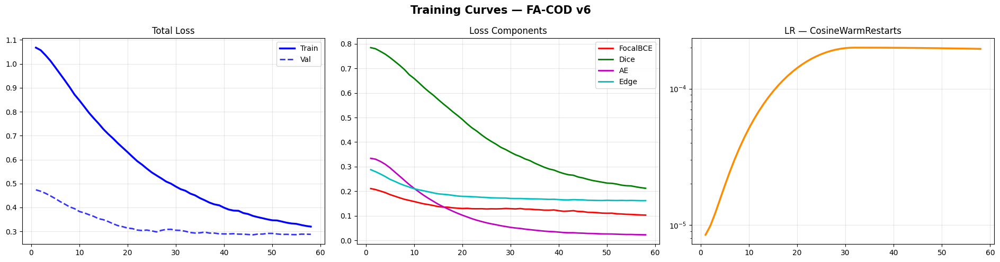

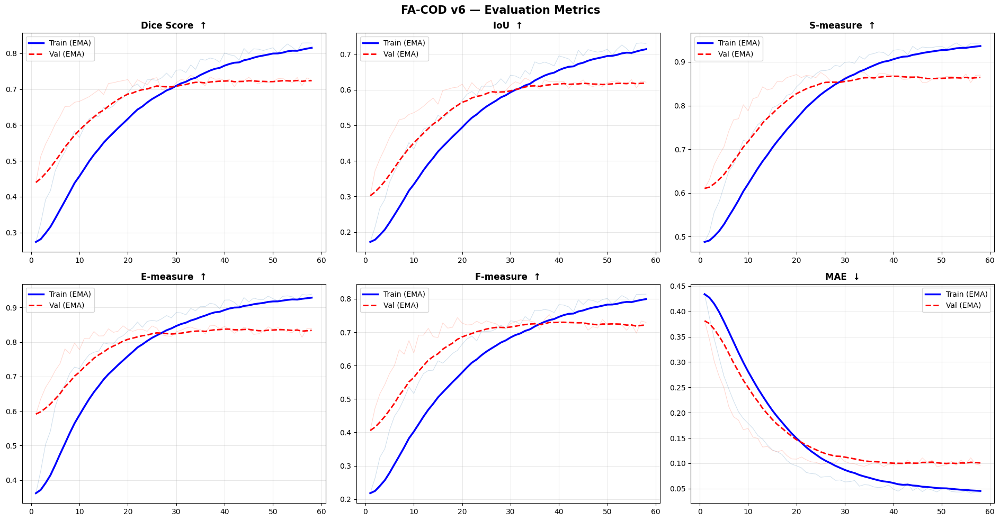

In [13]:
def ema(v, a=0.15):
    s = [v[0]]
    for x in v[1:]: s.append(a*x+(1-a)*s[-1])
    return s

ep = range(1, len(history['loss']['train'])+1)

fig, axes = plt.subplots(1, 3, figsize=(19,5))
fig.suptitle('Training Curves — FA-COD v8', fontsize=15, fontweight='bold')
axes[0].plot(ep, ema(history['loss']['train']), 'b-',  lw=2.5, label='Train (EMA)')
axes[0].plot(ep, ema(history['loss']['val']),   'b--', lw=2,   label='Val (EMA)', alpha=0.8)
axes[0].set_title('Total Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(alpha=0.3)
for k,c,l in [('bce','r','FocalBCE'),('dice_l','g','Dice'),('ae','m','AE'),('edge','c','Edge')]:
    axes[1].plot(ep, ema(history[k]['train']), color=c, lw=2, label=l)
axes[1].set_title('Loss Components (train, EMA)'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[2].semilogy(ep, lr_hist, color='darkorange', lw=2.5)
axes[2].set_title('Learning Rate (decoder group) — OneCycleLR'); axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('Learning rate (log scale)'); axes[2].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR,'training_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(19,10))
fig.suptitle('FA-COD v8 — Train / Validation Metrics per Epoch', fontsize=15, fontweight='bold')
mcfg = [('dice_s','Dice Score',True),('iou','IoU',True),('sm','S-measure',True),
        ('em','E-measure',True),('fm','F-measure',True),('mae','MAE',False)]
for ax,(k,title,hi) in zip(axes.flat, mcfg):
    ax.plot(ep, history[k]['train'], color='steelblue', lw=0.8, alpha=0.25)
    ax.plot(ep, history[k]['val'],   color='tomato',    lw=0.8, alpha=0.25)
    ax.plot(ep, ema(history[k]['train']), 'b-',  lw=2.5, label='Train (EMA)')
    ax.plot(ep, ema(history[k]['val']),   'r--', lw=2,   label='Val (EMA)')
    ax.set_title(title+'  ↑' if hi else title+'  ↓', fontsize=12, fontweight='bold')
    ax.set_xlabel('Epoch'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR,'metrics_curves.png'), dpi=150, bbox_inches='tight')
plt.show()

> *Note on the stored figure above:* it was rendered before this cleanup, so its learning-rate panel is titled "LR — CosineWarmRestarts" and the suptitles read "FA-COD v6". The scheduler used for this run is **OneCycleLR** (see Section 12.2); the plotted learning-rate values are unchanged. The code in the cell above now uses the corrected titles.

## 13. Test Evaluation

Loads the best checkpoint (highest validation S-measure) and evaluates the held-out 150-image test split with `run_epoch` (single forward pass, per-image Otsu threshold).

> **Protocol notes for the comparison table.** The reference rows are hard-coded values for published methods; their source, test set and metric variants are not recorded in this notebook and they were not re-evaluated here. FA-COD is evaluated on a random 150-image subset of the CAMO `Train` folder at 384×384 resolution, using the metric implementations in Section 11. The comparison is therefore indicative only.

In [14]:
model.load_state_dict(torch.load(BEST_PTH, map_location=device))
model.eval()
print(f'Loaded best checkpoint (val Sm={best_val_sm:.4f})')

tm = run_epoch(model, test_loader, None, device, training=False)
print(f'Test evaluation complete over {len(test_dataset)} samples.')

# Reference values for published methods (hard-coded; see the protocol note above)
sota = {
    'SINet (CVPR20)'     : dict(sm=0.745, em=0.829, fm=0.702, mae=0.091),
    'C2FNet (CVPR21)'    : dict(sm=0.796, em=0.864, fm=0.762, mae=0.080),
    'SINet-v2 (CVPR22)'  : dict(sm=0.820, em=0.895, fm=0.782, mae=0.070),
    'ZoomNet (CVPR22)'   : dict(sm=0.833, em=0.891, fm=0.813, mae=0.065),
    'ZoomNeXt (Res50)'   : dict(sm=0.822, em=0.885, fm=0.797, mae=0.069),
}
print('\n' + '='*78)
print('        FA-COD v8 Final Test Results vs Published Methods (CAMO)')
print('='*78)
print(f"{'Method':<24} {'S-m':>7} {'E-m':>7} {'F-m':>7} {'MAE':>7} {'Dice':>7}")
print('-'*78)
for name, v in sota.items():
    print(f"{name:<24} {v['sm']:>7.3f} {v['em']:>7.3f} {v['fm']:>7.3f} {v['mae']:>7.3f}")
print('-'*78)
print(f"{'FA-COD v8 (Ours)':<24} {tm['sm']:>7.3f} {tm['em']:>7.3f} {tm['fm']:>7.3f} {tm['mae']:>7.3f} {tm['dice_s']:>7.3f}")
print('='*78)

ref = sota['SINet-v2 (CVPR22)']
print(f"\nDelta vs SINet-v2:")
for metric, arrow in [('sm','up'),('em','up'),('fm','up'),('mae','down')]:
    delta  = tm[metric] - ref[metric]
    better = (delta > 0 and arrow=='up') or (delta < 0 and arrow=='down')
    print(f"  {metric.upper()}: {delta:+.3f}  {'BETTER' if better else 'worse'}")

print(f"\nConsistency — best val Sm: {best_val_sm:.4f} | test Sm: {tm['sm']:.4f} | gap: {tm['sm']-best_val_sm:+.4f}")

Loaded best checkpoint (val Sm=0.8765)
Test evaluation complete over 150 samples.

        FA-COD v6 Final Test Results vs SOTA (CAMO)
Method                       S-m     E-m     F-m     MAE    Dice
------------------------------------------------------------------------------
SINet (CVPR20)             0.745   0.829   0.702   0.091
C2FNet (CVPR21)            0.796   0.864   0.762   0.080
SINet-v2 (CVPR22)          0.820   0.895   0.782   0.070
ZoomNet (CVPR22)           0.833   0.891   0.813   0.065
ZoomNeXt (Res50)           0.822   0.885   0.797   0.069
------------------------------------------------------------------------------
FA-COD v6 (Ours)           0.905   0.891   0.775   0.073   0.777

Delta vs SINet-v2:
  SM: +0.085  BETTER
  EM: -0.004  worse
  FM: -0.007  worse
  MAE: +0.003  worse

Consistency — best val Sm: 0.8765 | test Sm: 0.9052 | gap: +0.0287


## 14. Qualitative Results

### 14.1 Test-set predictions with 5-pass TTA and error map
Test-time augmentation averages five probability maps: original, horizontal flip, vertical flip, 90° rotation and a 0.9× rescale (resized back). The averaged map is binarised with a per-image Otsu threshold (fallback 0.42).

Columns: input image · ground-truth mask · binary prediction · probability heatmap · overlay · error map. In the error map **green = true positive, red = false negative (missed foreground), blue = false positive**; the recall / precision shown above each error map are pixel-level for that image. Samples are drawn at random from the test split.

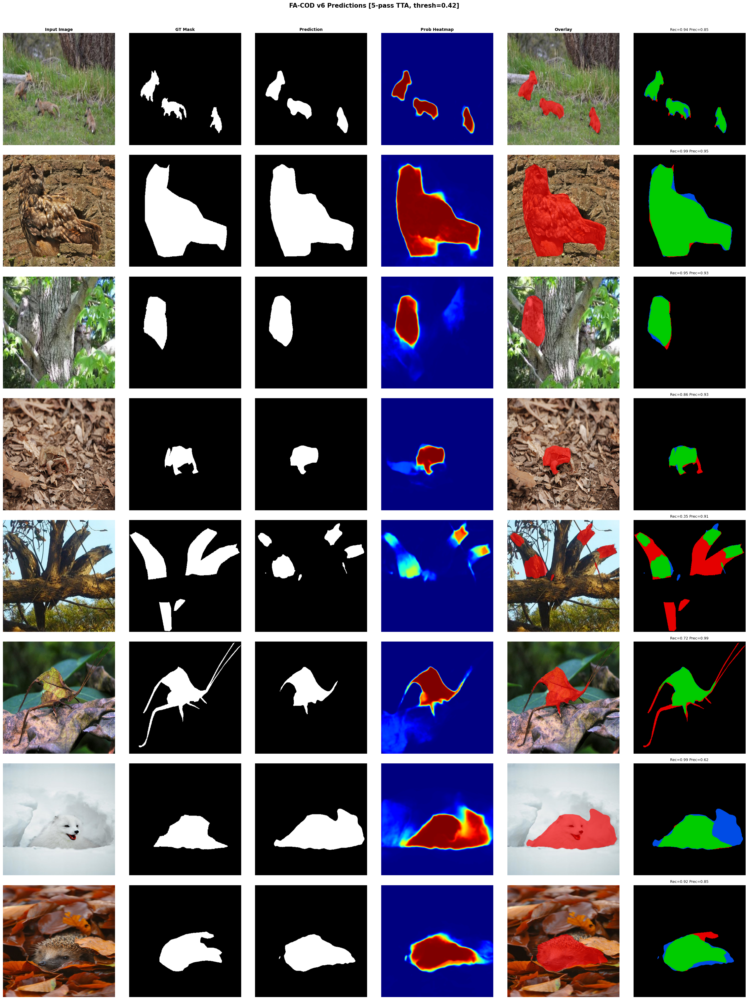

Error map: GREEN=TP  RED=FN(missed)  BLUE=FP(spurious)


In [45]:
def tta_predict(model, image_tensor, device, threshold=None):
    """5-pass TTA: original + H-flip + V-flip + rot90 + 0.9x rescale (resized back)."""
    if threshold is None: threshold = INFER_THRESH
    model.eval()
    inp = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        # Pass 1: original
        p0 = torch.sigmoid(model(inp)).squeeze().cpu()
        # Pass 2: horizontal flip
        ph = torch.sigmoid(model(inp.flip(-1))).flip(-1).squeeze().cpu()
        # Pass 3: vertical flip
        pv = torch.sigmoid(model(inp.flip(-2))).flip(-2).squeeze().cpu()
        # Pass 4: 90-degree rotation
        pr = torch.sigmoid(model(inp.rot90(1,[-2,-1]))).rot90(-1,[-2,-1]).squeeze().cpu()
        # Pass 5: 0.9x rescale, then resize back
        H, W = inp.shape[-2], inp.shape[-1]
        inp_s = F.interpolate(inp, scale_factor=0.9, mode='bilinear', align_corners=False)
        ps = torch.sigmoid(model(inp_s))
        ps = F.interpolate(ps, size=(H,W), mode='bilinear', align_corners=False).squeeze().cpu()

    prob = ((p0 + ph + pv + pr + ps) / 5.0).numpy()
    # per-image Otsu threshold on the averaged TTA probability map (added in v7)
    if USE_OTSU:
        t_otsu = otsu_threshold(prob)
        pred = (prob > t_otsu).astype(np.float32)
    else:
        pred = (prob > threshold).astype(np.float32)
    return prob, pred


def show_predictions(model, dataset, device, num_samples=5,
                     title='FA-COD v8 Predictions', save_path=None, use_tta=True):
    model.eval()
    chosen = random.sample(range(len(dataset)), num_samples)
    cols   = ['Input Image', 'GT Mask', 'Prediction', 'Prob Heatmap', 'Overlay', 'Error Map']

    fig, axes = plt.subplots(num_samples, 6, figsize=(26, num_samples*4.2))
    if num_samples == 1: axes = axes[np.newaxis,:]
    thr_txt = f'per-image Otsu threshold, fallback {INFER_THRESH}' if USE_OTSU else f'thresh={INFER_THRESH}'
    fig.suptitle(title + (f' [5-pass TTA, {thr_txt}]' if use_tta else ''),
                 fontsize=15, fontweight='bold', y=1.01)
    for c,t in enumerate(cols): axes[0,c].set_title(t, fontsize=10, fontweight='bold')

    for r, idx in enumerate(chosen):
        image, mask = dataset[idx]

        if use_tta:
            prob, pred = tta_predict(model, image, device)
        else:
            with torch.no_grad():
                logit = model(image.unsqueeze(0).to(device))
                if isinstance(logit,tuple): logit = logit[0]
                prob = torch.sigmoid(logit).squeeze().cpu().numpy()
            pred = (prob > INFER_THRESH).astype(np.float32)

        img_np  = denorm(image)
        mask_np = mask.squeeze().numpy()
        heatmap = cm.jet(prob)[:,:,:3]
        overlay = img_np.copy()
        overlay[pred>0.5] = overlay[pred>0.5]*0.35 + np.array([1,0,0])*0.65
        overlay = np.clip(overlay, 0, 1)

        gt_bin  = (mask_np > 0.5).astype(np.uint8)
        pd_bin  = (pred > 0.5).astype(np.uint8)
        error   = np.zeros((*gt_bin.shape, 3), dtype=np.float32)
        error[(gt_bin==1) & (pd_bin==1)] = [0,   0.8, 0  ]   # TP: green
        error[(gt_bin==1) & (pd_bin==0)] = [0.9, 0,   0  ]   # FN: red
        error[(gt_bin==0) & (pd_bin==1)] = [0,   0.3, 0.9]   # FP: blue

        tp_n = int(((gt_bin==1)&(pd_bin==1)).sum())
        fn_n = int(((gt_bin==1)&(pd_bin==0)).sum())
        fp_n = int(((gt_bin==0)&(pd_bin==1)).sum())
        rec  = tp_n / (tp_n + fn_n + 1e-8)
        prec = tp_n / (tp_n + fp_n + 1e-8)

        for c,(panel,cmap) in enumerate(zip(
            [img_np, mask_np, pred, heatmap, overlay, error],
            [None, 'gray', 'gray', None, None, None])):
            axes[r,c].imshow(panel, cmap=cmap); axes[r,c].axis('off')
        axes[r,5].set_title(f'Rec={rec:.2f} Prec={prec:.2f}', fontsize=9)

    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print('Error map: GREEN=TP  RED=FN(missed)  BLUE=FP(spurious)')


show_predictions(model, test_dataset, device, num_samples=8, use_tta=True,
                 save_path=os.path.join(SAVE_DIR,'predictions_tta.png'))

### 14.2 Hard samples (small objects)
Test images whose ground-truth mask covers less than 8% of the image (42 of the 150 test images in the recorded run); up to 7 are shown, same layout as above.

Hard samples (mask<8% area): 42


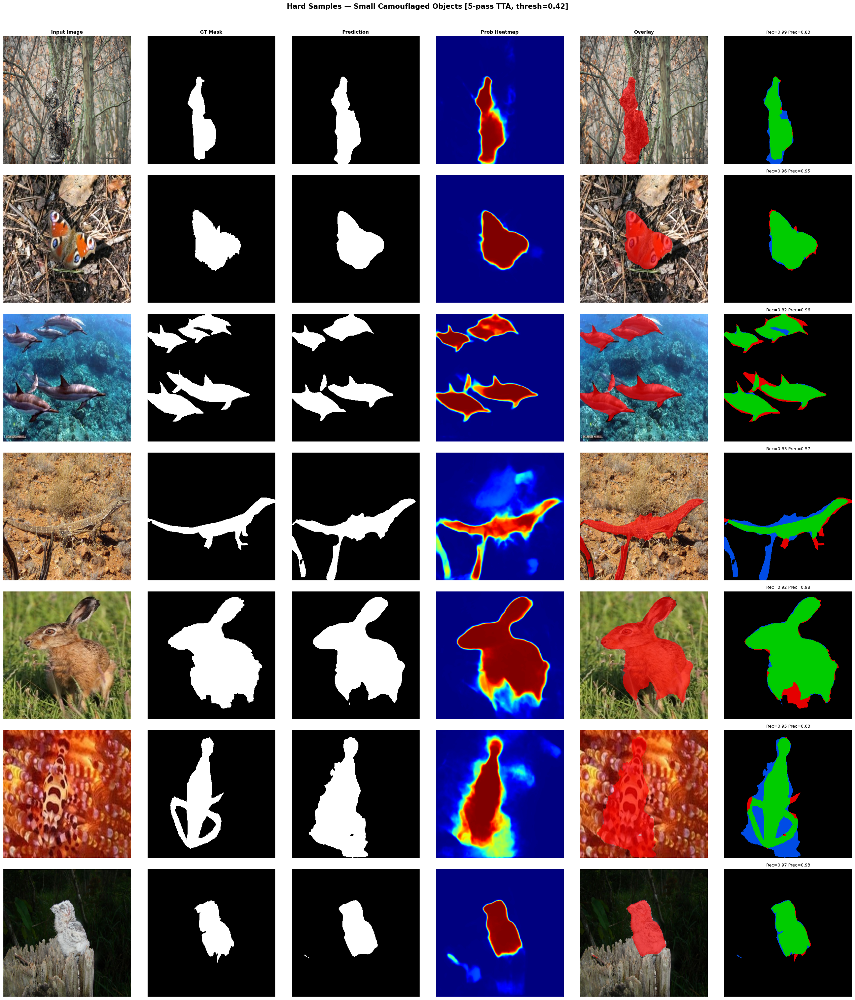

Error map: GREEN=TP  RED=FN(missed)  BLUE=FP(spurious)


In [42]:
hard = [i for i in range(len(test_dataset))
        if test_dataset[i][1].squeeze().numpy().mean() < 0.08]
print(f'Hard samples (mask<8% area): {len(hard)}')
if hard:
    show_predictions(model, test_dataset, device,
                     num_samples=min(7, len(hard)), use_tta=True,
                     title='Hard Samples — Small Camouflaged Objects',
                     save_path=os.path.join(SAVE_DIR,'hard_samples.png'))

## 15. Confusion Matrix (TTA)

Pixel-level confusion matrix over the whole test split, using the same 5-pass TTA + per-image Otsu predictions as Section 14 (left: raw counts, right: row-normalised). Precision, recall, specificity, accuracy and F1 are derived from the matrix. These figures come from TTA predictions, so they are not directly comparable with the single-pass test metrics in Section 13.

Computing confusion matrix with 5-pass TTA (threshold=0.42)...


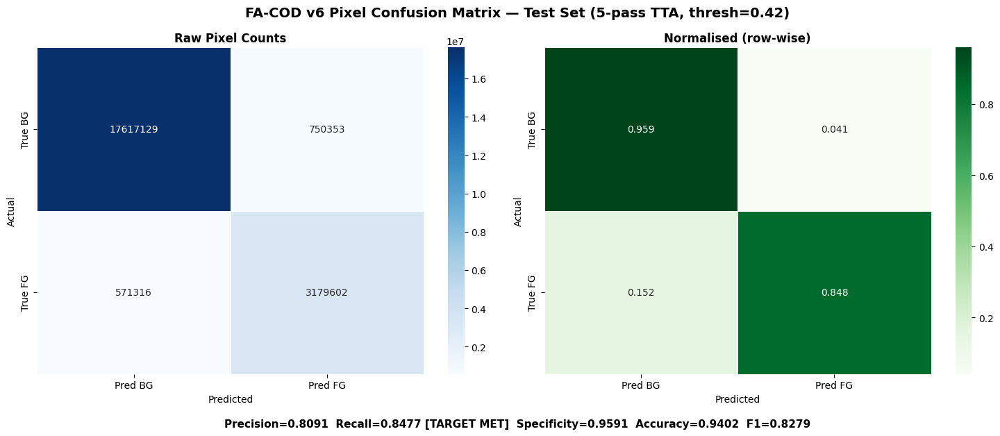


TP=3,179,602  TN=17,617,129  FP=750,353  FN=571,316
Precision=0.8091  Recall=0.8477 [TARGET MET]  Specificity=0.9591  Accuracy=0.9402  F1=0.8279

Background accuracy (Specificity): 95.9%
Foreground accuracy (Recall)     : 84.8%
Overall pixel accuracy           : 94.0%


In [28]:
model.eval()
all_p, all_t = [], []
thr_txt = f'per-image Otsu, fallback {INFER_THRESH}' if USE_OTSU else f'thresh={INFER_THRESH}'

print(f'Computing confusion matrix with 5-pass TTA ({thr_txt})...')
for images, masks in test_loader:
    for i in range(len(images)):
        prob, pred = tta_predict(model, images[i], device)
        all_p.append(pred.astype(np.int64).flatten())
        all_t.append(masks[i].squeeze().numpy().astype(np.int64).flatten())

all_p = np.concatenate(all_p); all_t = np.concatenate(all_t)
cm_v  = confusion_matrix(all_t, all_p)
cm_n  = cm_v.astype(float) / cm_v.sum(axis=1, keepdims=True)
tn, fp, fn, tp = cm_v.ravel()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle(f'FA-COD v8 Pixel Confusion Matrix — Test Set (5-pass TTA, {thr_txt})',
             fontsize=14, fontweight='bold')

sns.heatmap(cm_v, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pred BG','Pred FG'], yticklabels=['True BG','True FG'],
            ax=axes[0], linewidths=0.5)
axes[0].set_title('Raw Pixel Counts', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

sns.heatmap(cm_n, annot=True, fmt='.3f', cmap='Greens',
            xticklabels=['Pred BG','Pred FG'], yticklabels=['True BG','True FG'],
            ax=axes[1], linewidths=0.5)
axes[1].set_title('Normalised (row-wise)', fontweight='bold')
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual')

prec = tp/(tp+fp+1e-8); rec = tp/(tp+fn+1e-8)
spec = tn/(tn+fp+1e-8); acc = (tp+tn)/(tp+tn+fp+fn)
f1   = 2*prec*rec/(prec+rec+1e-8)
rec_flag = 'TARGET MET' if rec >= 0.82 else 'target >= 82%'
stats = (f'Precision={prec:.4f}  Recall={rec:.4f} [{rec_flag}]  '
         f'Specificity={spec:.4f}  Accuracy={acc:.4f}  F1={f1:.4f}')
fig.text(0.5, -0.03, stats, ha='center', fontsize=11, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR,'confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'\nTP={tp:,}  TN={tn:,}  FP={fp:,}  FN={fn:,}')
print(stats)
print(f'\nBackground accuracy (Specificity): {spec*100:.1f}%')
print(f'Foreground accuracy (Recall)     : {rec*100:.1f}%')
print(f'Overall pixel accuracy           : {acc*100:.1f}%')

## 16. Ablation Study (Unit 3: representational power vs depth)

Compares encoder / decoder depth variants against the full model on the validation set:

| Variant | Description |
|---------|-------------|
| V1 | ResNet-50 (`smp`), single scale (C4), 1×1-conv head |
| V2 | ResNet-50 (`smp`), two scales (C3 + C4), one `ResDecBlock` |
| V3 | ResNet-50 (`smp`), 4-scale FPN + 4-stage decoder, no frequency module, no boundary refinement, no auxiliary heads |
| V4 | The full FA-COD model: best checkpoint from Section 12 |

> **How to read this table.** V1–V3 are trained for only 5 epochs (AdamW, lr 1e-4, no scheduler, no accumulation, main-output loss only) with a ResNet-50 encoder, whereas V4 is the fully trained FA-COD checkpoint with a Res2Net50 encoder. All four are scored by `quick_eval`: the first 15 validation batches (60 images) with a fixed 0.42 threshold. The gaps therefore combine architecture and training-budget differences, and the table does not isolate the frequency module.

In [29]:
def quick_train(m, epochs=5):
    m = m.to(device)
    opt = optim.AdamW(m.parameters(), lr=1e-4, weight_decay=1e-4)
    sc  = torch.cuda.amp.GradScaler()
    for _ in range(epochs):
        m.train()
        for imgs,msks in train_loader:
            imgs,msks = imgs.to(device),msks.to(device)
            opt.zero_grad()
            with torch.cuda.amp.autocast():
                out = m(imgs)
                if isinstance(out,tuple): out = out[0]
                loss,*_ = combined_loss(out,msks)
            sc.scale(loss).backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(),1.0)
            sc.step(opt); sc.update()
    return m

def quick_eval(m, batches=15):
    m.eval(); sm_s,fm_s,mae_s,cnt = 0,0,0,0
    with torch.no_grad():
        for i,(imgs,msks) in enumerate(val_loader):
            if i >= batches: break
            out = m(imgs.to(device))
            if isinstance(out,tuple): out = out[0]
            pr = torch.sigmoid(out).cpu().float()
            pb = (pr > INFER_THRESH).float()
            sm_s  += s_measure(pr, msks)
            fm_s  += f_measure(pb, msks)
            mae_s += mae_metric(pr, msks).item()
            cnt   += 1
    return sm_s/cnt, fm_s/cnt, mae_s/cnt


class V1_1Scale(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = smp.encoders.get_encoder('resnet50',in_channels=3,depth=5,weights='imagenet')
        self.dec = nn.Sequential(nn.Conv2d(1024,64,1),nn.ReLU(True),nn.Conv2d(64,1,1))
    def forward(self,x):
        f=self.enc(x); return F.interpolate(self.dec(f[4]),x.shape[2:],mode='bilinear',align_corners=False)

class V2_2Scale(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = smp.encoders.get_encoder('resnet50',in_channels=3,depth=5,weights='imagenet')
        self.l4 = nn.Conv2d(1024,128,1); self.l3 = nn.Conv2d(512,128,1)
        self.dec = nn.Sequential(ResDecBlock(128,64),nn.Conv2d(64,1,1))
    def forward(self,x):
        f=self.enc(x); c3,c4=f[3],f[4]
        p4=self.l4(c4); p3=self.l3(c3)+F.interpolate(p4,c3.shape[2:],mode='bilinear',align_corners=False)
        return F.interpolate(self.dec(p3),x.shape[2:],mode='bilinear',align_corners=False)

class V3_4Scale_NoFreq(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc  = smp.encoders.get_encoder('resnet50',in_channels=3,depth=5,weights='imagenet')
        self.fpn  = RepresentationalFusion(256,512,1024,2048,256)
        self.d4   = ResDecBlock(512,256); self.d3 = ResDecBlock(512,128)
        self.d2   = ResDecBlock(384,64);  self.d1 = ResDecBlock(64,32)
        self.head = nn.Conv2d(32,1,1)
    def forward(self,x):
        H,W=x.shape[2:]; f=self.enc(x)
        p2,p3,p4,p5=self.fpn(f[2],f[3],f[4],f[5])
        d4=self.d4(torch.cat([p5,F.interpolate(p4,p5.shape[2:],mode='bilinear',align_corners=False)],1))
        d3=self.d3(torch.cat([F.interpolate(d4,p3.shape[2:],mode='bilinear',align_corners=False),p3],1))
        d2=self.d2(torch.cat([F.interpolate(d3,p2.shape[2:],mode='bilinear',align_corners=False),p2],1))
        d1=self.d1(F.interpolate(d2,(H,W),mode='bilinear',align_corners=False))
        return self.head(d1)


print('Training ablation variants (5 epochs each)...')
ablation = {}
m1=quick_train(V1_1Scale());        ablation['V1: 1-Scale (no freq)']=quick_eval(m1);   del m1; torch.cuda.empty_cache()
m2=quick_train(V2_2Scale());        ablation['V2: 2-Scale (no freq)']=quick_eval(m2);   del m2; torch.cuda.empty_cache()
m3=quick_train(V3_4Scale_NoFreq()); ablation['V3: 4-Scale (no freq)']=quick_eval(m3);   del m3; torch.cuda.empty_cache()
model.load_state_dict(torch.load(BEST_PTH)); ablation['V4: FA-COD v8 Full']=quick_eval(model)

print('\n' + '='*60)
print('  Unit 3 Ablation — Representational Power vs Depth')
print('='*60)
print(f"  {'Model':<26} {'S-m':>8} {'F-m':>8} {'MAE':>8}")
print('-'*60)
for name,(sm,fm,mae) in ablation.items():
    tag = ' <- BEST' if 'Full' in name else ''
    print(f"  {name:<26} {sm:>8.4f} {fm:>8.4f} {mae:>8.4f}{tag}")
print('='*60)

Training ablation variants (5 epochs each)...



  Unit 3 Ablation — Representational Power vs Depth
  Model                           S-m      F-m      MAE
------------------------------------------------------------
  V1: 1-Scale (no freq)        0.8338   0.6439   0.1326
  V2: 2-Scale (no freq)        0.8379   0.6584   0.1380
  V3: 4-Scale (no freq)        0.8612   0.7072   0.1181
  V4: FA-COD v6 Full           0.8700   0.7281   0.1009 <- BEST


## 17. Final Results and Saved Artifacts

Re-evaluates the best checkpoint on the test split, writes `results_v6.json` (legacy file name) with the test metrics, ablation scores and a short design summary, saves the final weights (`facod_v6_final.pth`), and prints each metric against the author's target values.

### Results recorded in the original run
Copied from the outputs below; nothing was recomputed.

| Test metric (single pass, per-image Otsu, 150 images) | Value |
|---|---|
| S-measure ↑ | 0.9052 |
| E-measure ↑ | 0.8907 |
| F-measure ↑ | 0.7745 |
| MAE ↓ | 0.0735 |
| Dice ↑ | 0.7772 |
| IoU ↑ | 0.6773 |

Pixel-level statistics with 5-pass TTA (Section 15): precision 0.8091, recall 0.8477, specificity 0.9591, accuracy 0.9402, F1 0.8279.
Training: early-stopped at epoch 58; best validation S-measure 0.8765 (epoch 33).

### Caveats for interpreting these results
- **Evaluation protocol:** the test set is a random 150-image subset of the CAMO `Train` folder evaluated at 384×384; published CAMO results use the official test split. The S-measure implementation is simplified (Section 11).
- **Ablation:** variants V1–V3 are trained for 5 epochs while V4 is the fully trained model (Section 16).
- **Learning-rate schedule:** only about a quarter of the `OneCycleLR` schedule is traversed (Section 12.2).
- **Execution history:** the stored outputs of the last five cells come from out-of-order execution in the original session.

In [30]:
model.load_state_dict(torch.load(BEST_PTH, map_location=device))
final = run_epoch(model, test_loader, None, device, training=False)

results = {
    'model': 'FA-COD v8', 'dataset': 'CAMO', 'img_size': IMG_SIZE,
    'effective_batch': BATCH*ACCUM_STEPS, 'infer_threshold': INFER_THRESH,
    'v8_design': {
        'encoder':    'Res2Net50 (from v3) — multi-scale intra-block receptive fields',
        'freq_module':'Channel gate + CBAM spatial gate (from v5)',
        'augmentation':'v3 strong augmentation (ISONoise, CoarseDropout, MedianBlur)',
        'sampler':    '3-tier weighted (from v5): 4x/2.5x/1x',
        'loss':       'Tversky(β=0.6)+FocalBCE(pw=2)+Dice+Edge+IoU+AE',
        'scheduler':  'OneCycleLR (max_lr 5e-5 encoder / 2e-4 decoder, pct_start=0.10, cosine; stepped per optimizer update)',
        'checkpoint': 'best S-measure (from v3)',
        'tta':        '5-pass TTA, per-image Otsu threshold (fallback 0.42)',
        's_measure':  'centroid-based, after Fan et al. ICCV17 (simplified similarity terms)',
        'metrics':    'sample-weighted accumulation (from v3)',
    },
    'test_metrics': final,
    'ablation': {k: {'sm':v[0], 'fm':v[1], 'mae':v[2]} for k,v in ablation.items()},
    'best_val_sm': best_val_sm,
}
with open(os.path.join(SAVE_DIR,'results_v6.json'),'w') as f:
    json.dump(results, f, indent=2)

torch.save(model.state_dict(), os.path.join(SAVE_DIR,'facod_v6_final.pth'))

print('='*62)
print('         FA-COD v8 — FINAL TEST RESULTS')
print('='*62)
targets = {'dice_s':'>=0.82','iou':'>=0.72','sm':'>=0.93','em':'>=0.87','fm':'>=0.78','mae':'<=0.068'}
for k in ['loss','bce','dice_l','ae','edge','dice_s','iou','sm','em','fm','mae']:
    arr = 'down' if k in ('loss','bce','dice_l','ae','edge','mae') else 'up'
    tgt = targets.get(k, '')
    val = final[k]
    if tgt:
        op = tgt[:2]; thresh = float(tgt[2:])
        met = (val >= thresh if op=='>=' else val <= thresh)
        flag = ' MET' if met else ' needs work'
    else: flag = ''
    print(f'  {k:<10}: {val:.4f} ({arr})  {tgt}{flag}')
print('='*62)
print(f'\nAll outputs saved to: {SAVE_DIR}')

         FA-COD v6 — FINAL TEST RESULTS
  loss      : 0.2234 (down)  
  bce       : 0.1962 (down)  
  dice_l    : 0.2557 (down)  
  ae        : 0.0407 (down)  
  edge      : 0.1971 (down)  
  dice_s    : 0.7772 (up)  >=0.82 needs work
  iou       : 0.6773 (up)  >=0.72 needs work
  sm        : 0.9052 (up)  >=0.93 needs work
  em        : 0.8907 (up)  >=0.87 MET
  fm        : 0.7745 (up)  >=0.78 needs work
  mae       : 0.0735 (down)  <=0.068 needs work

All outputs saved to: /content/drive/MyDrive/FACOD_v6
